# Tools - flow in networks II
This notebook presents some tools related to (laminar) flow in a graph (network):
- solving flow problem with boundary conditions
- computing equivalent resistance between any pair of nodes (and between two disjoint set of nodes - not realistic physically)

*Note. Presented tool works on `networkx.Graph` objects. A `KGraph` object `kg` can be defined from a `networkx.Graph` graph `g` with `kg = kn.from_networkx(g)`.*

## Flow equations
Consider an undirected weighted graph $G=(V, E)$ with $\omega(e)>0$ the weight on the edge $e\in E$. Note $V=\{v_1, \ldots, v_n\}$ the set of nodes a(vertices) and $\omega_{ij} = \omega(e)$ if $e = \{v_i, v_j\} \in E$ and $\omega_{ij}=0$ otherwise. Note that an edge $\{v_i, v_j\}$ in $E$ can be noted $v_i\sim v_j$ or even $ij$.

Let $L$ be the Laplacian matrix of the graph $G$, weighted by conductances $\omega_{ij}. Given a source term $q^{\textit{ext}}$ consisting of the entering flux at graph nodes (from the exterior), the node potential $p$ is the solution of the equation (in matrix form) $L p = q^{\textit{ext}}$.

See notebook `H1-Flow-in-networks-I.ipynb` for details.

### Flow equations with boundary conditions

Consider a partition $\mathcal{I} \sqcup \mathcal{B} = \{1, \ldots, n\}$ of (the indices of) the graph nodes and write the flow equation $L\cdot p = q$ (with $L = L_{\omega}$ and $q = q^{ext}$) as
- $L_{\mathcal{I}\mathcal{I}}\cdot p_{\mathcal{I}} + L_{\mathcal{I}\mathcal{B}}\cdot p_{\mathcal{B}} = q_{\mathcal{I}}$
- $L_{\mathcal{B}\mathcal{I}}\cdot p_{\mathcal{I}} + L_{\mathcal{B}\mathcal{B}}\cdot p_{\mathcal{B}} = q_{\mathcal{B}}$

where
- $p = \left(\begin{array}{c}p_\mathcal{I} \\ p_\mathcal{B} \end{array}\right), \qquad q = \left(\begin{array}{c}q_\mathcal{I} \\ q_\mathcal{B} \end{array}\right) \qquad \text{and}\qquad L = \left(\begin{array}{cc}L_{\mathcal{I}\mathcal{I}} & L_{\mathcal{I}\mathcal{B}} \\ L_{\mathcal{B}\mathcal{I}} & L_{\mathcal{B}\mathcal{B}} \end{array}\right)$.

Assume that
- $p_\mathcal{B}$ is given, i.e. the potentials at nodes $\mathcal{B}$ are known (boundary condition),
- $q_\mathcal{I}$ is given, i.e. the fluxes entering the network at nodes $\mathcal{I}$ are known (source term);

the goal is then to determine $p_I$ and $q_B$, which are unknown. 

Provided that the subgraph $G(I)$ induced by the nodes $\mathcal{I}$ is connected, i.e. removing the nodes $\mathcal{B}$ from $G$ does not disconnect the graph, the matrix $L_{\mathcal{I}\mathcal{I}}$ is invertible, and
- $p_\mathcal{I} = {L_{\mathcal{I}\mathcal{I}}}^{-1}\left(q_\mathcal{I} - L_{\mathcal{I}\mathcal{B}}\cdot p_\mathcal{B}\right)$

The entering fluxes at the nodes $\mathcal{B}$ are then
- $q_{\mathcal{B}} = L_{\mathcal{B}\mathcal{I}}\cdot p_{\mathcal{I}} + L_{\mathcal{B}\mathcal{B}}\cdot p_{\mathcal{B}}$.

#### Remark
If $G(I)$ is not connected (i.e. has more than one connected component), the problem is decomposed as follows.
Let $I_1, \ldots, I_m$ the partition of the set $I$, such that the induced subgraphs $G(I_1), \ldots, G(I_m)$ are the connected components of $G(I)$. For each subset $I_k$ of $I$, let $G_k$ be the connected component of the subgraph induced by the union of $I_k$ and $B$ that contains the nodes $I_k$. Let $B_k$ be the nodes of $B$ in $G_k$ (some nodes in $B$ may have been removed to have a connected graph, that is $B_k$ may be not equal to $B$). Then, $G_k = G(I_k, B_k)$ is the subragph induced by the inner nodes $I_k$ and the boundary nodes $B_k$. The flow problem is then solved for each $G_k$ as explained above, providing the potentials $p_{I_k}$ at the nodes $I_k$ and  the fluxes $q_{B_k}$ entering at the nodes $B_k$. The solution of the flow problem in the entire graph is then obtained by gathering the vectors $p_{I_k}$ to get the potentials $p_I$ at the nodes $I$, and by gathering the vectors $q_{B_k}$ and summing the values at the common nodes, to get the fluxes $q_B$ entering at the nodes $B$.




In [1]:
import networkx as nx
import numpy as np 
import matplotlib.pyplot as plt
import scipy
import time

In [2]:
# Choose matplotlib backend
# -------------------------
# 'inline' : inline plot (non-interactive)
# 'widget' : interactive plot
# 'tk'     : plot in a pop-up window (interactive)
from IPython import get_ipython
get_ipython().run_line_magic('matplotlib', 'inline')
# get_ipython().run_line_magic('matplotlib', 'widget')
# get_ipython().run_line_magic('matplotlib', 'tk')

# Or simply:
# %matplotlib inline
# %matplotlib widget
# %matplotlib tk


In [3]:
# import pyvista as pv

# # Choose backend for pyvista with jupyter
# # ---------------------------------------
# pv.set_jupyter_backend('static') # static plots
# # pv.set_jupyter_backend('trame')  # 3D-interactive plots

# # Notes:
# # -> ignored if run in a standard python shell
# # -> use keyword argument "notebook=False" in Plotter() to open figure in a pop-up window

In [4]:
import karstnet as kn
print(f'Karstnet version: {kn.__version__}')

Karstnet version: 1.4.6


## Illustration on a small graph in 2D
A 2D example - a graph generated from a Delaunay triangulation of points.

In [5]:
# Options for plot of 2D graph
options = {
    'node_size'   : 150,         # node size
    'linewidths'  : 1,           # node border width       
    'edgecolors'  : 'gray',      # node border color
    'node_color'  : 'lightblue', # node color (default - if no attribute is specified or for nan values)
    'width'       : 1,           # edge width
    'edge_color'  : 'gray',      # edge color (default - if no attribute is specified or for nan values)
    'with_labels' : True,        # show node labels ?
    'font_size'   : 8,           # font size for labels
    #
    # axes
    'show_ticks'  : True,        # show ticks ?
    'axis_equal'  : True         # aspect ratio equal ?
}

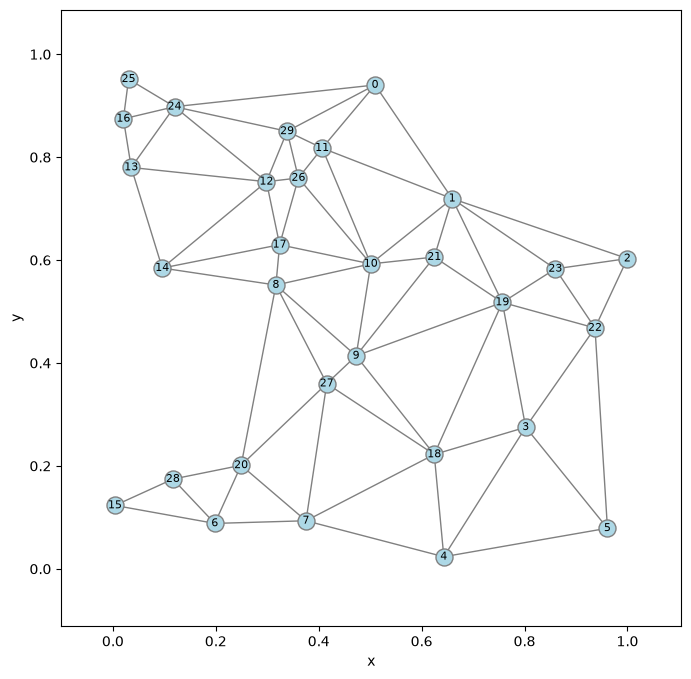

In [6]:
# Number of points and seed
npoints = 30
seed = 35306

# Generate random points uniformly in [0, 1] x [0, 1]
np.random.seed(seed)
points = np.random.random(size=(npoints, 2))

# Generate 2D graph from Delaunay triangulation of the points,
# edges whose length are less (resp. greater) than a mininmal (resp. maximal) valuse are removed
g = kn.misc.graph_from_delaunay_tri(points,min_edge_len=0.01, max_edge_len=0.4)

# Keep the largest connected component
g = kn.utils.get_list_of_connected_components(g, order='descending', renumbering_nodes=True)[0]

# Plot the graph
plt.figure(figsize=(8, 8))
kn.view.plot_graph2d(g, **options)
plt.show()

- Add a node with a string as label to check that the developed algorithms work property

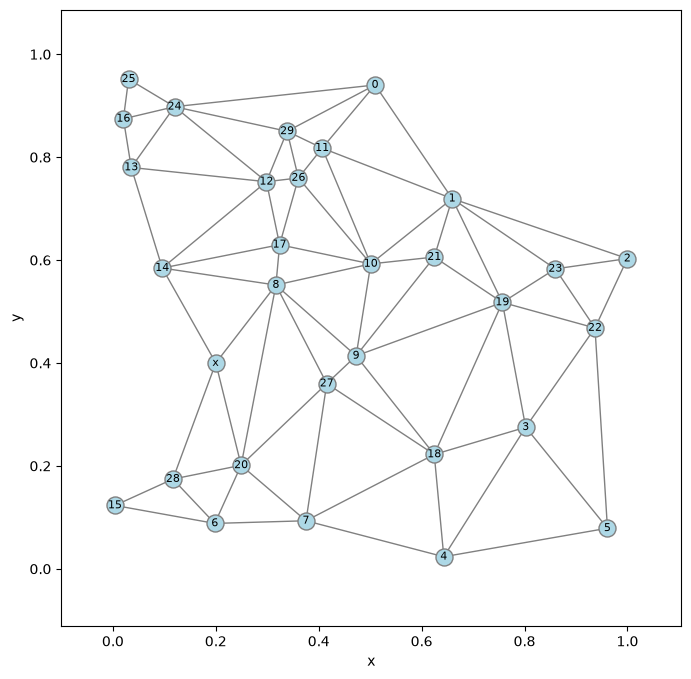

In [7]:
# Add a node with label 'x' and some edges
g.add_node('x')
g.nodes['x']['pos'] = np.array([0.2, 0.4])
g.add_edges_from([('x', i) for i in [8, 14, 28, 20]])

# Plot the graph
plt.figure(figsize=(8, 8))
kn.view.plot_graph2d(g, **options)
plt.show()

### Set edge weight (conductance $\omega$)

In [8]:
# Set edge weight (w) (conductance)
# ---------------------------------
# # Uniform (constant)
# w = {e: 1.0 for e in g.edges()} # unweigted graph (specifying argument edge_weight=None in the functions below)

# # Set random conductance on edges - U([0, 1])
# np.random.seed(1211)
# w_arr = np.random.rand(len(g.edges()))
# w = {e: wi for e, wi in zip(g.edges(), w_arr)}

# # Set random conductance on edges - lognormal, log weight ~ N(m, s^2)
# np.random.seed(353)
# m = 0.0
# s = 1.0
# w_arr = np.exp(scipy.stats.norm(loc=m, scale=s).rvs(g.number_of_edges())) # random values in log-normal distribution
# w = {e: wi for e, wi in zip(g.edges(), w_arr)}

# Inverse of edge length
w = kn.utils.get_edge_length_dict(g, 'pos', exponent=-1)
# w = {e: 1.0/np.sqrt(np.sum((np.asarray(g.nodes[e[0]]['pos']) - np.asarray(g.nodes[e[1]]['pos']))**2)) for e in g.edges()} # Equiv.

nx.set_edge_attributes(g, w, 'w')


### Plot conductances

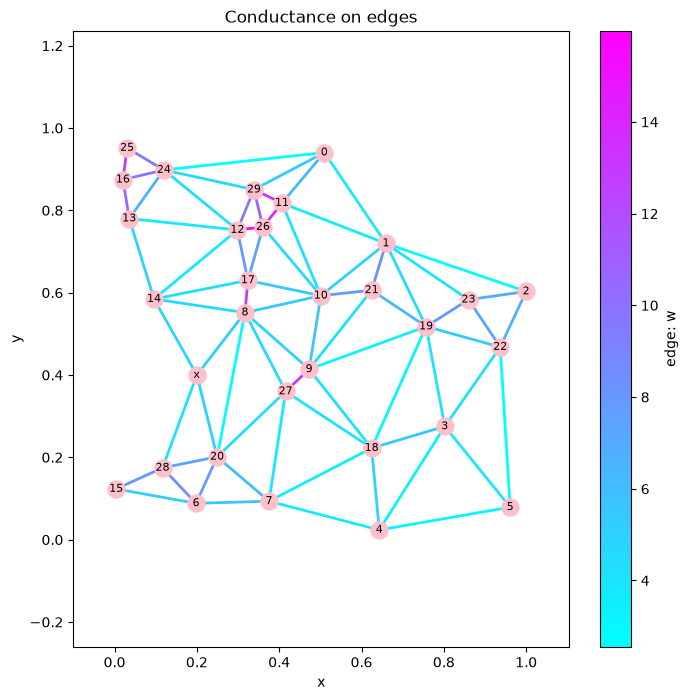

In [9]:
options = {
    'node_size'   : 150,         # node size
    'node_color'  : 'pink',      # node color (default - if no attribute is specified or for nan values)
    'width'       : 2,           # edge width
    'edge_color'  : 'gray',      # edge color (default - if no attribute is specified or for nan values)
    'with_labels' : True,        # show node labels ?
    'font_size'   : 8,           # font size for labels
    #
    # axes
    'show_ticks'  : True,
    'axis_equal'  : True
}

plt.figure(figsize=(8, 8))
kn.view.plot_graph2d(
    g,
    node_attr=None, 
    edge_attr='w', edge_cmap='cool',
    **options)
plt.title('Conductance on edges')
plt.show()

### Plot conductances - edge width proportional to conductance

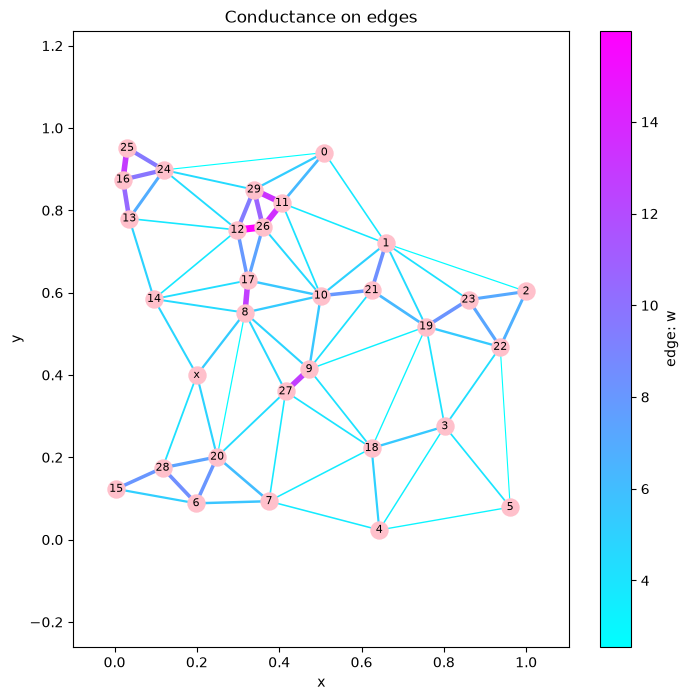

In [10]:
options = {
    'node_size'   : 150,         # node size
    'node_color'  : 'pink',      # node color (default - if no attribute is specified or for nan values)
    'edge_color'  : 'gray',      # edge color (default - if no attribute is specified or for nan values)
    'with_labels' : True,        # show node labels ?
    'font_size'   : 8,           # font size for labels
    #
    # axes
    'show_ticks'  : True,
    'axis_equal'  : True
}

# Edge width for 'w' and 'q'
w = np.asarray(list(nx.get_edge_attributes(g, 'w').values()))
w_width_max = 5
w_width = w/w.max() * w_width_max

plt.figure(figsize=(8, 8))
kn.view.plot_graph2d(
    g,
    node_attr=None, 
    edge_attr='w', edge_cmap='cool',
    width = w_width, # set edge  width
    **options)
plt.title('Conductance on edges')
plt.show()

## Flow in the network with boundary condition
Boundary nodes:
- $\mathcal{B} = \mathcal{B}_1 \sqcup \mathcal{B}_2$, with 
    - $p(u) = 1.0$ for $u\in\mathcal{B}_1$, nodes at the left of the domain
    - $p(u) = 0.0$ for $u\in\mathcal{B}_2$, nodes at the right of the domain

Inner nodes:
- $\mathcal{I}= V\setminus \mathcal{B}$, with $q(u)$ = 0 for $u\in\mathcal{I}$.

*Note: see notebook `H3-Flow-in-networks-III.ipynb` for an example where the node potential is fixed to 0.0 on the nodes at the right of the domain, and entering flux is fixed to 1.0 at the nodes at the left of the border (and to 0.0 at the nodes in the "middle").*

In [11]:
# Boundary nodes label
B1_nodes_label = [25, 16, 13, 14, 'x', 28, 15] 
B2_nodes_label = [2, 22, 5] 
# B_nodes_label = B1_nodes_label + B2_nodes_label

# Potential at boundary nodes
pB1_nodes_dict = {u: 1.0 for u in B1_nodes_label}
pB2_nodes_dict = {u: 0.0 for u in B2_nodes_label}
# - merge dictionaries
pB_nodes_dict = pB1_nodes_dict
pB_nodes_dict.update(pB2_nodes_dict)

# Inner nodes label
I_nodes_label = [k for k in g.nodes() if k not in pB_nodes_dict.keys()]

# Source term (entering flux) at inner nodes
qI_nodes_dict = {k: 0.0 for k in I_nodes_label}

# Solve flow
p_nodes_dict, q_nodes_dict = kn.tools.solve_flow_with_bc(
                                g, 
                                pB_nodes_dict=pB_nodes_dict, 
                                qI_nodes_dict=qI_nodes_dict, 
                                edge_weight='w', 
                                return_entering_fluxes=True)

# Set node potential as node attribute in graph `g`
nx.set_node_attributes(g, p_nodes_dict, 'potential')

# Add entering flux as node attribute 'entering_flux'
nx.set_node_attributes(g, q_nodes_dict, 'entering_flux')

# Absolute flows along edges
# --------------------------
# Compute absolute flows along edges
edge_abs_flow_dict = kn.tools.compute_abs_flow_along_edges(g, edge_weight='w', node_potential='potential')

# Set absolute flow as edge attribute in graph `g`
nx.set_edge_attributes(g, edge_abs_flow_dict, 'q_abs')

# Flows along edges - directed graph
# ----------------------------------
g_dir = kn.tools.compute_directed_graph_of_flow(g, edge_weight='w', node_potential='potential', edge_flow='q')
# -> directed graph with flow as edge attributes - only the edges with positive (or zero) flow are kept

### Do some checks

In [12]:
# Check local equation on each edge
ok = np.allclose(
    [g.edges[u, v]['q_abs'] - g.edges[u, v]['w'] * np.abs(g.nodes[u]['potential'] - g.nodes[v]['potential'])
        for u, v in g.edges()], 
    0)
print(f'Local equations ok ? {ok}')


Local equations ok ? True


In [13]:
# Check:
# - flux = 0 along edges linking 2 nodes in B1_nodes_label
d = nx.get_edge_attributes(g, 'q_abs')
for u in B1_nodes_label:
    for v in B1_nodes_label:
        if (u, v) in d.keys():
            print(f'edge: {u} ~ {v}, flux: {d[(u, v)]:.4g}')


edge: 16 ~ 25, flux: 0
edge: 13 ~ 16, flux: 0
edge: 13 ~ 14, flux: 0
edge: 14 ~ x, flux: 0
edge: 28 ~ x, flux: 0
edge: 15 ~ 28, flux: 0


In [14]:
# Check:
# - flux = 0 along edges linking 2 nodes in B2_nodes_label
d = nx.get_edge_attributes(g, 'q_abs')
for u in B2_nodes_label:
    for v in B2_nodes_label:
        if (u, v) in d.keys():
            print(f'edge: {u} ~ {v}, flux: {d[(u, v)]:.4g}')


edge: 2 ~ 22, flux: 0
edge: 5 ~ 22, flux: 0


In [15]:
# Check entering flux on boundary nodes
d = nx.get_node_attributes(g, 'entering_flux')

for u in B1_nodes_label:
    print(f'node: {u}, entering flux: {d[u]:.4g}')  

print()    

for u in B2_nodes_label:
    print(f'node: {u}, entering flux: {d[u]:.4g}')  

print()    

s = np.sum(list(d.values()))
print(f'sum of entering fluxes: {s:.4g}')
print(f'sum of entering fluxes close to zero ? {np.isclose(s, 0)}')


node: 25, entering flux: 0.5955
node: 16, entering flux: 0.6069
node: 13, entering flux: 1.034
node: 14, entering flux: 2.336
node: x, entering flux: 1.722
node: 28, entering flux: 1.888
node: 15, entering flux: 0.5221

node: 2, entering flux: -2.537
node: 22, entering flux: -4.023
node: 5, entering flux: -2.145

sum of entering fluxes: 7.105e-15
sum of entering fluxes close to zero ? True


### Plot result (1) - undirected graph
Plot node potential and absolute edge flow.

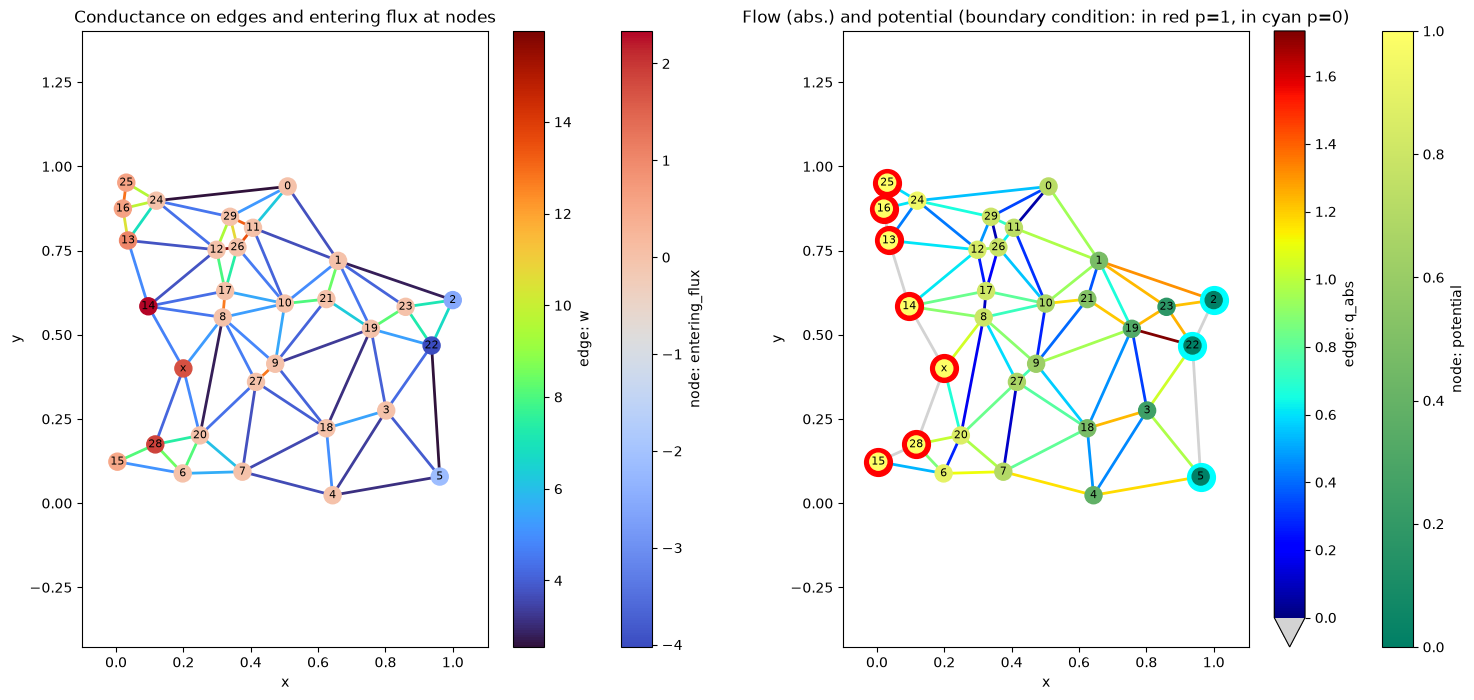

In [16]:
# Common options for plot of 2D graph
options = {
    'node_size'   : 150,         # node size
    'node_color'  : 'pink',      # node color (default - if no attribute is specified or for nan values)
    'width'       : 2,           # edge width
    'edge_color'  : 'gray',      # edge color (default - if no attribute is specified or for nan values)
    'with_labels' : True,        # show node labels ?
    'font_size'   : 8,           # font size for labels
    #
    # axes
    'show_ticks'  : True,
    'axis_equal'  : True
}

# Plot
# ====
plt.subplots(1,2, figsize=(18, 8))

# Plot - entering flux at nodes and conductance on edges
# ------------------------------------------------------
plt.subplot(1,2,1)
kn.view.plot_graph2d(
    g,
    node_attr='entering_flux', cmap='coolwarm',
    edge_attr='w', edge_cmap='turbo',
    **options)
plt.title('Conductance on edges and entering flux at nodes')

# Plot - potential on nodes and absolute flow on edges
# --------------------------------------------------
# Color map for node attribute (potential)
cmap = 'summer'

# Color map for edge attribute (flow)
edge_cmap = plt.get_cmap('jet')
edge_cmap.set_under('lightgray') # color for value below lower limit 'edge_vmin' (if specified) / distinguish zero-flow
edge_vmin = 1.e-10

plt.subplot(1,2,2)
kn.view.plot_graph2d(
    g, 
    node_attr='potential', cmap=cmap,
    edge_attr='q_abs', edge_cmap=edge_cmap, edge_vmin=edge_vmin,
    options_edge_colorbar={'extend':'min'},
    **options)

# ... highlight boundary nodes
plt.scatter(*np.asarray([g.nodes[u]['pos'] for u in B1_nodes_label]).T, marker='o', s=400, color='red',  alpha=1)
plt.scatter(*np.asarray([g.nodes[u]['pos'] for u in B2_nodes_label]).T, marker='o', s=400, color='cyan', alpha=1)

plt.title(f'Flow (abs.) and potential (boundary condition: in red p=1, in cyan p=0)')

plt.show()


### Plot results (2) - directed graph

Plot node potential and oriented edge flow.

*Note. With directed graph, the color bar can not be displayed, because the function `nx.draw_networkx_edges` does not return any "mappable" required for plotting color bar. To display the color bar, one can first employ the undirected graph with absolute values of flow on edges, and then utilize the directed graph to show the oriented edges (see below).*

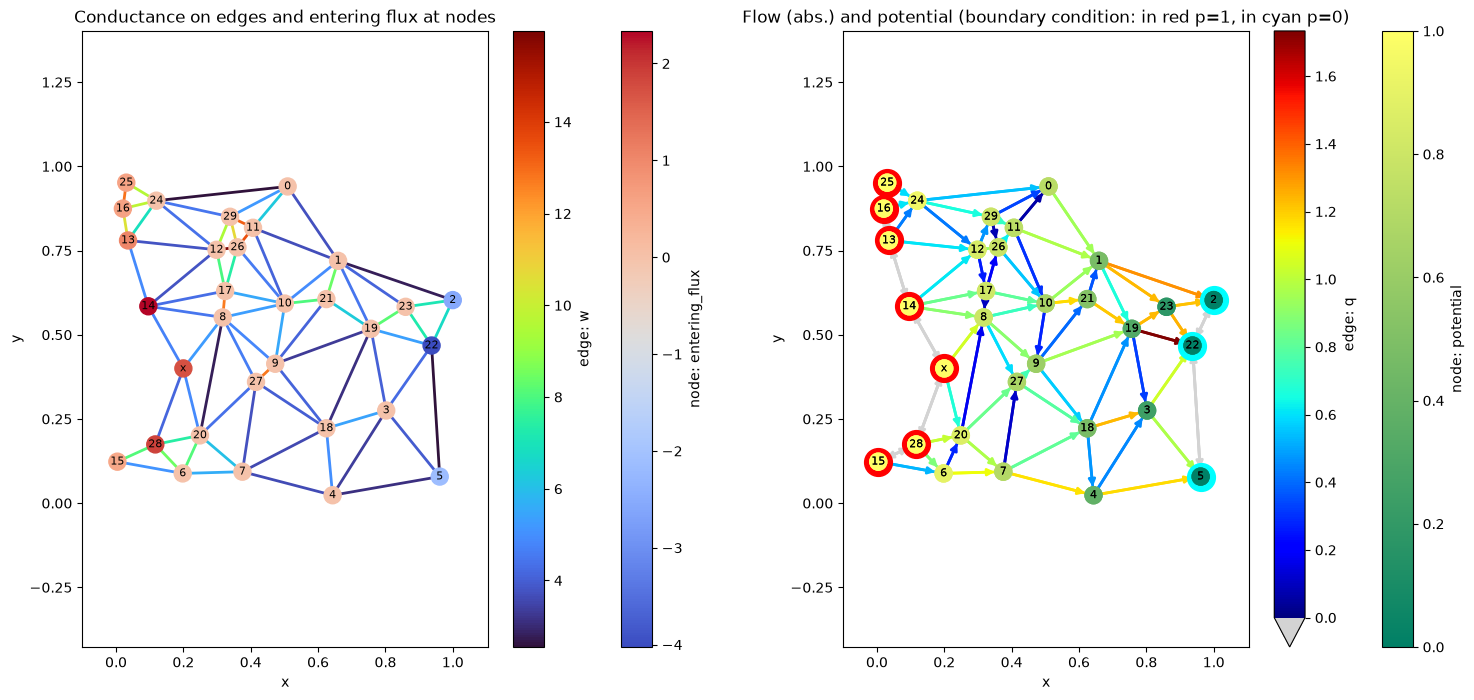

In [17]:
# Common options for plot of 2D graph
options = {
    'node_size'   : 150,         # node size
    'node_color'  : 'pink',      # node color (default - if no attribute is specified or for nan values)
    'width'       : 2,           # edge width
    'edge_color'  : 'gray',      # edge color (default - if no attribute is specified or for nan values)
    'with_labels' : True,        # show node labels ?
    'font_size'   : 8,           # font size for labels
    #
    # axes
    'show_ticks'  : True,
    'axis_equal'  : True
}

# Plot
# ----
plt.subplots(1,2, figsize=(18, 8))

# Plot - entering flux at nodes and conductance on edges
# ------------------------------------------------------
plt.subplot(1,2,1)
kn.view.plot_graph2d(
    g,
    node_attr='entering_flux', cmap='coolwarm',
    edge_attr='w', edge_cmap='turbo',
    **options)
plt.title('Conductance on edges and entering flux at nodes')

# Plot - potential on nodes and absolute flow on edges
# ----------------------------------------------------
# Color map for node attribute (potential)
cmap = 'summer'

# Color map for edge attribute (flow)
edge_cmap = plt.get_cmap('jet')
edge_cmap.set_under('lightgray') # color for value below lower limit 'edge_vmin' (if specified) / distinguish zero-flow
edge_vmin = 1.e-10

plt.subplot(1,2,2)

# ... display unoriented edge with color bar
kn.view.plot_graph2d(
    g, 
    node_attr='potential', cmap=cmap,
    edge_attr='q_abs', edge_cmap=edge_cmap, edge_vmin=edge_vmin,
    options_edge_colorbar={'label':'edge: q', 'extend':'min'},
    **options)

# ... display the oriented edges without color bar
kn.view.plot_graph2d(
    g_dir, 
    node_attr='potential', cmap=cmap, 
    show_node_colorbar=False, # already displayed with plot of g_sol above
    edge_attr='q', edge_cmap=edge_cmap, edge_vmin=edge_vmin,
    show_edge_colorbar=False, # already displayed with plot of g_sol above 
                              # note: with oriented graph, color bar can not be displayed
                              # (function 'nx.draw_networkx_edges' not mappable)
    **options)

# ... highlight boundary nodes
plt.scatter(*np.asarray([g.nodes[u]['pos'] for u in B1_nodes_label]).T, marker='o', s=400, color='red',  alpha=1)
plt.scatter(*np.asarray([g.nodes[u]['pos'] for u in B2_nodes_label]).T, marker='o', s=400, color='cyan', alpha=1)

plt.title(f'Flow (abs.) and potential (boundary condition: in red p=1, in cyan p=0)')
plt.show()


### Plot results (3) - directed graph - custom
Plot node potential and oriented edge flow ; set edge width according to values and add edge labels.

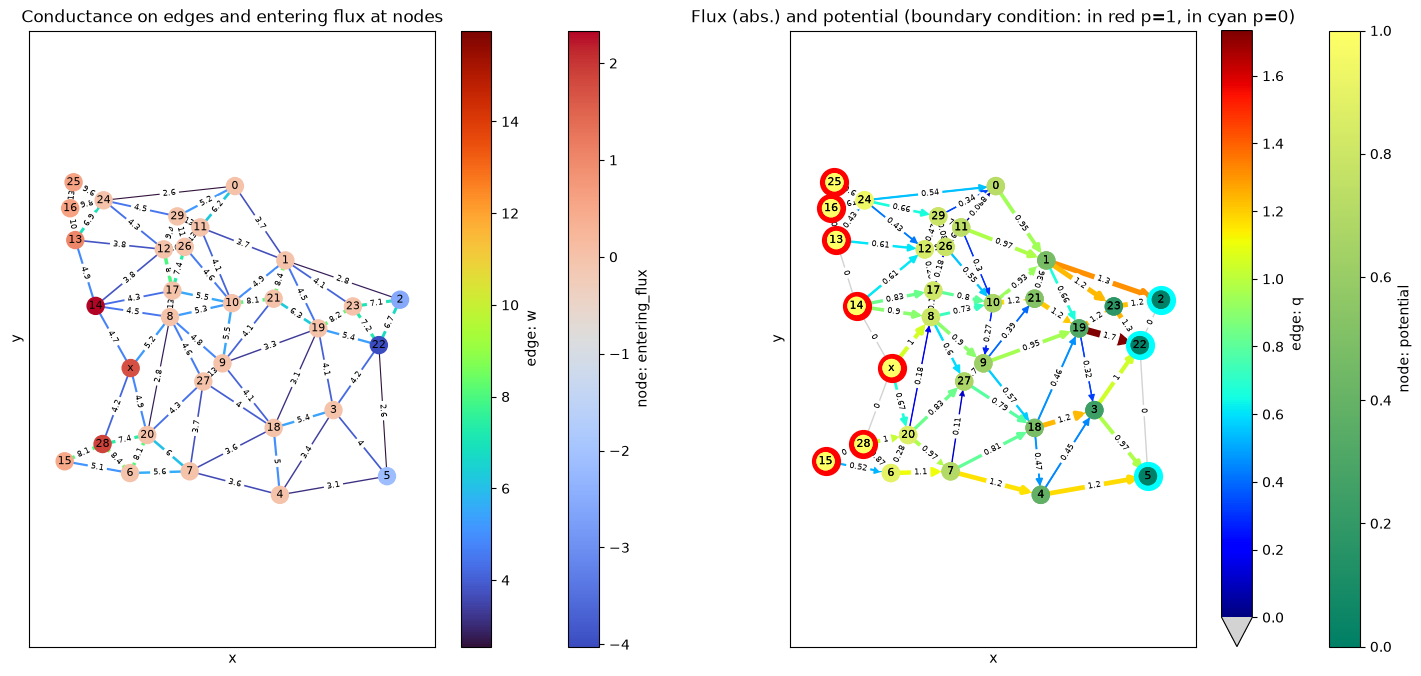

In [18]:
# Common options for plot of 2D graph
options = {
    'node_size'   : 150,         # node size
    'node_color'  : 'pink',      # node color (default - if no attribute is specified or for nan values)
    # 'width'       : 2,           # edge width
    'edge_color'  : 'gray',      # edge color (default - if no attribute is specified or for nan values)
    'with_labels' : True,        # show node labels ?
    'font_size'   : 8,           # font size for labels
    #
    # axes
    'show_ticks'  : True,
    'axis_equal'  : True
}

# Edge width for 'w' and 'q'
w = np.asarray(list(nx.get_edge_attributes(g, 'w').values()))
w_width_max = 5
w_width = w/w.max() * w_width_max

q = np.abs(np.asarray(list(nx.get_edge_attributes(g_dir, 'q').values())))
q_width_max = 5
q_width = q/q.max() * q_width_max

# Node position
pos = nx.get_node_attributes(g, 'pos')

# Plot
# ====
plt.subplots(1,2, figsize=(18, 8))

# Plot - entering flux at nodes and conductance on edges
# ------------------------------------------------------
plt.subplot(1,2,1)
kn.view.plot_graph2d(
    g,
    node_attr='entering_flux', cmap='coolwarm',
    edge_attr='w', edge_cmap='turbo',
    width = w_width, # set edge  width
    **options)

# ... add edge labels
edge_labels = {k:f'{v:.2g}' for k, v in nx.get_edge_attributes(g, 'w').items()}
nx.draw_networkx_edge_labels(g, pos=pos, edge_labels=edge_labels, font_color='black', font_size=6)

plt.title('Conductance on edges and entering flux at nodes')

# Plot - potential on nodes and absolute flow on edges
# --------------------------------------------------
# Color map for node attribute (potential)
cmap = 'summer'

# Color map for edge attribute (flow)
edge_cmap = plt.get_cmap('jet')
edge_cmap.set_under('lightgray') # color for value below lower limit 'edge_vmin' (if specified) / distinguish zero-flow
edge_vmin = 1.e-10

plt.subplot(1,2,2)

# ... display unoriented edge with color bar
kn.view.plot_graph2d(
    g, 
    node_attr='potential', cmap=cmap,
    edge_attr='q_abs', edge_cmap=edge_cmap, edge_vmin=edge_vmin,
    options_edge_colorbar={'label':'edge: q', 'extend':'min'},
    **options)

# ... display the oriented edges without color bar
kn.view.plot_graph2d(
    g_dir, 
    node_attr='potential', cmap=cmap, 
    show_node_colorbar=False, # already displayed with plot of g_sol above
    edge_attr='q', edge_cmap=edge_cmap, edge_vmin=edge_vmin,
    show_edge_colorbar=False, # already displayed with plot of g_sol above 
                              # note: with oriented graph, color bar can not be displayed
                              # (function 'nx.draw_networkx_edges' not mappable)
    width = q_width, # set edge  width
    **options)

# ...add edge labels
edge_labels = {k:f'{v:.2g}' for k, v in nx.get_edge_attributes(g, 'q_abs').items()}
nx.draw_networkx_edge_labels(g, pos=pos, edge_labels=edge_labels, font_color='black', font_size=6)

# ... highlight boundary nodes
plt.scatter(*np.asarray([g.nodes[u]['pos'] for u in B1_nodes_label]).T, marker='o', s=400, color='red',  alpha=1)
plt.scatter(*np.asarray([g.nodes[u]['pos'] for u in B2_nodes_label]).T, marker='o', s=400, color='cyan', alpha=1)

plt.title(f'Flux (abs.) and potential (boundary condition: in red p=1, in cyan p=0)')

plt.show()


## Equivalent resistance 
### Equivalent resistance between two distinct nodes
The equivalent resistance between two distinct nodes $a$ and $b$ is given by 
- $R^{\textit{eq}}_{ab} = (\delta_a - \delta_b)^\top \cdot L^{+}\cdot (\delta_a - \delta_b)$

where $L^{+}$ is the pseudo-inverse of the Laplacian matrix (weighted by edge conductance), see notebook `H1-Flow-in-networks-I.ipynb` for details.

### Equivalent resistance between two disjoint sets of nodes
Imposing a fixed difference between the average node potential over the first set and the average node potential over the second set, the result above can be extend as follows. 

Let $\mathcal{A}$ and $\mathcal{B}$ two disjoint sets of graph nodes, $\mathcal{A}, \mathcal{B} \subset V$ (the set of all graph nodes). With
- $\delta_{\mathcal{A}}\in \mathbb{R}^n,\ n=\vert V\vert\ \text{and, for}\ v\in V,\ \delta_\mathcal{A}(v) = \left\{\begin{array}{ll}1& \text{if } v\in\mathcal{A}\\0&\text{otherwise},\end{array}\right.$

the equivalent resistance between $\mathcal{A}$ and $\mathcal{B}$ is given by
- $R^{\textit{eq}}_{\mathcal{A}\mathcal{B}} = \left(\frac{1}{\vert \mathcal{A}\vert}\delta_{\mathcal{A}} - \frac{1}{\vert \mathcal{B}\vert}\delta_{\mathcal{B}}\right)^\top\cdot L^{+}\cdot\left(\frac{1}{\vert \mathcal{A}\vert}\delta_{\mathcal{A}} - \frac{1}{\vert \mathcal{B}\vert}\delta_{\mathcal{B}}\right).$

**Important remark. As defined here, the equivalent resistance between two set of nodes is not physically appropriate.**

In [19]:
# Compute (first) eigen values and eigen vectors of the Laplacian matrix,
# used further for (approximation) of the pseudo-inverse of the Laplacian matrix
k = None # maximum number of eigen values and eigen vectors to compute (None: all)

if k is None:
    print('Compute all eigen values and eigen vectors of the Laplacian matrix')
else:
    print(f'Compute the first {k} (at max.) eigen values and eigen vectors of the Laplacian matrix')

t1 = time.time()
lap_eigval, lap_eigvec = kn.tools.laplacian_eigs(g, edge_weight='w', k=k)
t2 = time.time()

print(f'Elapsed time: {t2-t1:.2f} sec')

Compute all eigen values and eigen vectors of the Laplacian matrix
Elapsed time: 0.00 sec


In [20]:
# Alternatives to compute equivalent resistance between two disjoint set of nodes
# -------------------------------------------------------------------------------
A_nodes_label = [25, 16, 13, 14, 'x', 28, 15] 
B_nodes_label = [2, 22, 5]

# A_nodes_label = ['x'] 
# B_nodes_label = [3]

# Method 1 : Use the dedicated function `kn.tools.equivalent_conductance_sets`
# --------
Req_AB_1 = kn.tools.equivalent_conductance_sets(g, [[A_nodes_label, B_nodes_label]], eigval=lap_eigval, eigvec=lap_eigvec) # using eigen values and eigen vectors already computed
# Req_AB_1 = kn.tools.equivalent_conductance_sets(g, [[A_nodes_label, B_nodes_label]], edge_weight='w', k=None)
Req_AB_1 = 1.0 / Req_AB_1[0]

# Method 2 : Use pre-computed eigen values and eigen vectors of the Laplacian matrix
# --------
# Set dictionary to convert node label to node index
node_label2index = kn.utils.get_node_label2index_dict(g)

A_nodes_index = [node_label2index[k] for k in A_nodes_label]
B_nodes_index = [node_label2index[k] for k in B_nodes_label]

Req_AB_2 = np.sum(1.0/lap_eigval[1:] * (lap_eigvec[A_nodes_index, 1:].mean(axis=0) - lap_eigvec[B_nodes_index, 1:].mean(axis=0))**2)

# # Or
# n_A_nodes = len(A_nodes_index)
# n_B_nodes = len(B_nodes_index)
# qext = np.zeros(g.number_of_nodes())
# for k in A_nodes_index:
#     qext[k] = 1.0/n_A_nodes
# for k in B_nodes_index:
#     qext[k] = -1.0/n_B_nodes
# p = lap_eigvec[:, 1:] @ (1.0/lap_eigval[1:] * (lap_eigvec[:, 1:].T @ qext))
# Req_AB_2 = qext @ p

# Results
# -------
print(f'All methods give same results ? {np.allclose([Req_AB_2], Req_AB_1)}')
print(f'Equivalent resistance  between node (label) set {A_nodes_label} and {B_nodes_label} : {Req_AB_1:.4g}')
print(f'Equivalent conductance between node (label) set {A_nodes_label} and {B_nodes_label} : {1.0/Req_AB_1:.4g}')

All methods give same results ? True
Equivalent resistance  between node (label) set [25, 16, 13, 14, 'x', 28, 15] and [2, 22, 5] : 0.1203
Equivalent conductance between node (label) set [25, 16, 13, 14, 'x', 28, 15] and [2, 22, 5] : 8.314



### Another approach
Instead of imposing the difference of the average potential between the two sets of nodes, one could impose the same potential $p_\mathcal{A}$ at all nodes in $\mathcal{A}$ and the same potential $p_\mathcal{B}$ at all nodes in $\mathcal{B}$, with $p_\mathcal{A} > p_\mathcal{B}$, which is a stronger constraint. Then, one could solve the flow problem with boundary condition with these given potentials for nodes in $\mathcal{A}$ and in $\mathcal{B}$, and none entering flux at inner nodes (nodes not in $\mathcal{A}$ or $\mathcal{B}$). Finally, by dividing the potential difference $p_\mathcal{A}-p_\mathcal{B}$ by the total (sum) of the entering fluxes at nodes in $\mathcal{A}$, one would get an equivalent resistance.

Following this approach, the potential difference is equal to zero between any pair of nodes in $\mathcal{A}$ (resp. $\mathcal{B}$), and then no flow circulates within $\mathcal{A}$ (resp. $\mathcal{B}$). As a consequence, since the flow crosses less edges, it is expected that the obtained equivalent resistance will be smaller (than the equivalent resistance based on the imposed difference between the average node potential over each set of nodes).

**Important remark. As defined here, the equivalent resistance between two set of nodes is not physically appropriate.**

In [21]:
# Approach by solving flow equations with boundary conditions
# -----------------------------------------------------------
# Potential at boundary nodes (constant on A and on B)
pA_nodes_dict = {u: 1.0 for u in A_nodes_label}
pB_nodes_dict = {u: 0.0 for u in B_nodes_label} # diff of one with nodes in A
# - merge dictionaries
pBC_nodes_dict = pA_nodes_dict
pBC_nodes_dict.update(pB_nodes_dict)

# Inner nodes label
I_nodes_label = [k for k in g.nodes() if k not in pBC_nodes_dict.keys()]

# Source term (entering flux) at inner nodes
qI_nodes_dict = {k: 0.0 for k in I_nodes_label}

# Solve flow
p_nodes_dict, q_nodes_dict = kn.tools.solve_flow_with_bc(
                                g, 
                                pBC_nodes_dict, 
                                qI_nodes_dict, 
                                edge_weight='w', 
                                return_entering_fluxes=True)
# -> p_nodes_dict: dictionary with node label as key and potential at node as value
# -> q_nodes_dict: dictionary with node label as key and entering flux at node as value

Req_AB_3 = 1.0 / np.sum([q_nodes_dict[u] for u in A_nodes_label])
print(f'Equivalent resistance between node (label) set {A_nodes_label} and {B_nodes_label}\n' +
      f'imposing constant potential on both sets: {Req_AB_3:.4g}')
print(f'- Smaller than or equal to value above ? {Req_AB_3 < Req_AB_1 or np.isclose(Req_AB_3, Req_AB_1)}')

Equivalent resistance between node (label) set [25, 16, 13, 14, 'x', 28, 15] and [2, 22, 5]
imposing constant potential on both sets: 0.1149
- Smaller than or equal to value above ? True


## Solving flow with flux entering at one inlet node and exiting at one outlet node

This case has been treated in the notebook `H1-Flow-in-networks-I.ipynb` by solving flow equation without boundary condition.

As an alternative, one can solve flow equation with boundary condition, by fixing the potential at the inlet and outlet node.

In [22]:
# Set inlet and outlet nodes (label)
node_inlet = 'x'
node_outlet = 3

### Solving flow without boundary condition
The source term is set with a given flux (e.g. of $1$) entering at inlet node and exiting at outlet node, and with entering flux of $0$ at other nodes.

In [23]:
# Compute (first) eigen values and eigen vectors of the Laplacian matrix,
# used further for (approximation) of the pseudo-inverse of the Laplacian matrix
k = None # maximum number of eigen values and eigen vectors to compute (None: all)

if k is None:
    print('Compute all eigen values and eigen vectors of the Laplacian matrix')
else:
    print(f'Compute the first {k} (at max.) eigen values and eigen vectors of the Laplacian matrix')

t1 = time.time()
lap_eigval, lap_eigvec = kn.tools.laplacian_eigs(g, edge_weight='w', k=k)
t2 = time.time()

print(f'Elapsed time: {t2-t1:.2f} sec')

Compute all eigen values and eigen vectors of the Laplacian matrix
Elapsed time: 0.00 sec


In [24]:
# Set source term (inject flux of 1 at inlet node and "pump" flux of -1 at outlet node)
q_nodes_dict_1 = {k:0.0 for k in g.nodes()} # flux at nodes
q_nodes_dict_1[node_inlet] = 1.0   # flux at inlet node
q_nodes_dict_1[node_outlet] = -1.0 # flux at outlet node

# Solve L p = qext, p potential at nodes
p_nodes_dict_1 = kn.tools.solve_flow_without_bc(g, q_nodes_dict=q_nodes_dict_1, eigval=lap_eigval, eigvec=lap_eigvec) # using pre-computed eigen valuse and eigen vector of the Laplacian matrix
# p_nodes_dict_1 = kn.tools.solve_flow_without_bc(g, q_nodes_dict=q_nodes_dict_1, edge_weight='w', k=None)
# -> p_nodes_dict_1: dictionary with node label as key and potential at node as value

In [25]:
# # Alternative
# # -----------
# # Set dictionary to convert node label to node index
# node_label2index = kn.utils.get_node_label2index_dict(g)
# # node_label2index = {u:i for i, u in enumerate(G.nodes())} # equiv.

# # Get node index of inlet node and outlet node
# i0, i1 = node_label2index[node_inlet], node_label2index[node_outlet]

# # Solve L p = qext, p potential at nodes
# p = lap_eigvec[:, 1:] @ (1.0/lap_eigval[1:] * (lap_eigvec[i0, 1:] - lap_eigvec[i1, 1:]))

# # Set dictionary of node potential
# # (dictionary with node label as key and potential at node as value)
# p_nodes_dict_1 = {u: p[node_label2index[u]] for u in g.nodes()}

# # Store source term (inject flux of 1 at inlet node and "pump" flux of -1 at outlet node)
# q_nodes_dict_1 = {k:0.0 for k in g.nodes()} # flux at nodes
# q_nodes_dict_1[node_inlet] = 1.0   # flux at inlet node
# q_nodes_dict_1[node_outlet] = -1.0 # flux at outlet node


### Solving flow with boundary condition
The potential is imposed at inlet node and outlet node (with a difference not equal to zero, e.g. potential of $1$ at inlet node and potential of $0$ at outlet node), and the source term is set at $0$ at inner nodes (nodes other than the inlet node and the outlet node).

In [26]:
# Fix potential at inlet and outlet nodes (boundary condition)
pBC_nodes_dict = {node_inlet: 1.0, node_outlet: 0.0}

# Source term (entering flux) at inner nodes (other than inlet and outlet)
qI_nodes_dict = {k: 0.0 for k in g.nodes() if k not in (node_inlet, node_outlet)}

# Solve flow
p_nodes_dict_2, q_nodes_dict_2 = kn.tools.solve_flow_with_bc(
                                g, 
                                pBC_nodes_dict, 
                                qI_nodes_dict, 
                                edge_weight='w', 
                                return_entering_fluxes=True)
# -> p_nodes_dict_2: dictionary with node label as key and potential at node as value
# -> q_nodes_dict_2: dictionary with node label as key and entering flux at node as value

### Comparison of the results
Let $p^{(1)}$ and $p^{(2)}$ the vector (array) of node potential and $q^{(1)}$ and $q^{(2)}$ the vector of entering flux at nodes, obtained respectively by the two methods.

As the entering flux is zero for all inner nodes, and $q^{(k)}(inlet) = -q^{(k)}(outlet)>0$ for $k=1,2$, we have
- $q^{(2)} = \alpha\cdot q^{(1)}$, for a constant $\alpha > 0$.

As $L p^{(1)} = q^{(1)}$ and $L p^{(2)} = q^{(2)}$, it follows $L (\alpha\cdot p^{(1)} - p^{(2)})=0$, i.e. $\alpha\cdot p^{(1)} - p^{(2)} \in \operatorname{Ker} L = \langle \mathbf{1} \rangle$ (where $\mathbf{1}$ is the vector of ones), and 
- $p^{(2)} = \alpha\cdot p^{(1)} + C \cdot \mathbf{1}$ for a constance $C\in \mathbb{R}$.

Note that the flows along edges are also multiplied by the factor $\alpha$ from the 1st to the 2nd case, because the difference of node potential between the two end nodes of any edge is multiplied by $\alpha$.

Hence, multiplying the node potential and the flow allows to control either the difference of node potential between the inlet and outlet nodes, or the amount of flow entering (exiting) the network at inlet node (outlet node).

In [27]:
p1 = np.asarray([p_nodes_dict_1[u] for u in g.nodes()]) # array of potential at nodes
p2 = np.asarray([p_nodes_dict_2[u] for u in g.nodes()])

q1 = np.asarray([q_nodes_dict_1[u] for u in g.nodes()]) # array of entering flux at nodes
q2 = np.asarray([q_nodes_dict_2[u] for u in g.nodes()])

alpha = q_nodes_dict_2[node_inlet] / q_nodes_dict_1[node_inlet]
C = p_nodes_dict_2[node_inlet] - alpha * p_nodes_dict_1[node_inlet]

print(np.allclose(q2, alpha * q1))     # Should be True
print(np.allclose(p2, alpha * p1 + C)) # Should be True

True
True
